In [1]:
!pip install yfinance pandas numpy scikit-learn shap matplotlib seaborn joblib


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    balanced_accuracy_score,
    roc_curve,
    roc_auc_score
)
from scipy.stats import randint, uniform, loguniform
from imblearn.pipeline import Pipeline as ImbPipeline
import shap
from sklearn.pipeline import Pipeline as SkPipeline



In [3]:
tickers = [
    # Core
    "INTC","AAPL","MSFT","NVDA","AMD",
    "CSCO","IBM","ORCL","TXN","QCOM",
    "AVGO","ADBE","CRM","AMAT","MU",

    # Software / Cloud
    "NOW","PANW","SNPS","CDNS","WDAY",
    "FTNT","TEAM","ZS","OKTA","CRWD",

    # Semiconductor
    "LRCX","KLAC","NXPI","MCHP","MRVL",
    "SWKS","ADI","ON","TER",

    # Hardware / Systems
    "HPQ","DELL","HPE",

    # Platforms
    "META","GOOGL"
]
print(f"Total tickers in sample: {len(tickers)}")

Total tickers in sample: 39


In [4]:
start_date = "2010-01-01"
end_date = "2025-01-01"

all_data = []
dropped_log = {}

for ticker in tickers:
    stock = yf.Ticker(ticker)
    hist = stock.history(start=start_date, end=end_date)

    if hist.empty:
        dropped_log[ticker] = "No price data returned by Yahoo Finance"
        continue

    # Annual aggregation using entire year
    annual = pd.DataFrame()
    annual["High"] = hist["High"].resample("YE").max()
    annual["Low"] = hist["Low"].resample("YE").min()
    annual["Close"] = hist["Close"].resample("YE").last()
    annual["Volume"] = hist["Volume"].resample("YE").sum()
    annual["Year"] = annual.index.year

    dividends = stock.dividends.resample("YE").sum()
    dividends = dividends.to_frame(name="Dividend")
    dividends["Year"] = dividends.index.year

    df = pd.merge(annual, dividends, on="Year", how="left")


    df["Dividend"] = df["Dividend"].fillna(0)

    # Market-based proxy features
    df["Price_Momentum"] = df["Close"].pct_change()
    df["Price_Range_Ratio"] = df["High"] / df["Low"]
    df["Volume_Momentum"] = df["Volume"].pct_change()

    df["Ticker"] = ticker

    all_data.append(df[[
        "Ticker","Year",
        "Price_Momentum",
        "Price_Range_Ratio",
        "Volume_Momentum",
        "Dividend"
    ]])

    n_rows = len(df)

    n_nan = df[["Price_Momentum","Price_Range_Ratio","Volume_Momentum"]].isna().any(axis=1).sum()
    if n_nan > 0:
        dropped_log[ticker] = f"{n_nan} of {n_rows} rows dropped due to NaN"

data = pd.concat(all_data, ignore_index=True)
data = data.sort_values(["Year","Ticker"]).reset_index(drop=True)

# Genuine future prediction: shift dividend forward by one year per company
data["Next_Dividend"] = data.groupby("Ticker")["Dividend"].shift(-1)

rows_before_shift_dropna = data.groupby("Ticker").size()
rows_after_shift_dropna = data.dropna(subset=["Next_Dividend"]).groupby("Ticker").size()

for ticker in tickers:
    before = rows_before_shift_dropna.get(ticker, 0)
    after = rows_after_shift_dropna.get(ticker, 0)
    if before > 0 and after == 0:
        dropped_log[ticker] = (
            f"All {before} year(s) of data lost at the T+1 shift step "
            f"(no valid next-year dividend pairing -- insufficient trading history)"
        )
    elif ticker not in rows_before_shift_dropna.index and ticker not in dropped_log:
        dropped_log[ticker] = "No usable rows after feature computation (upstream data issue)"

data = data.dropna(subset=["Next_Dividend"])
data["Target"] = (data["Next_Dividend"] > data["Dividend"]).astype(int)
data = data.drop(columns=["Next_Dividend"])

In [5]:
print(f"Rows before dropna: {len(data)}")
print(f"Companies before dropna: {data['Ticker'].nunique()}")

nan_by_ticker = data.groupby("Ticker")[["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Target"]].apply(
    lambda g: g.isna().any(axis=1).sum()
)
nan_by_ticker = nan_by_ticker[nan_by_ticker > 0]
if len(nan_by_ticker) > 0:
    print("\nRows with NaN per company (before dropna):")
    print(nan_by_ticker.to_string())

Rows before dropna: 498
Companies before dropna: 39

Rows with NaN per company (before dropna):
Ticker
AAPL     1
ADBE     1
ADI      1
AMAT     1
AMD      1
AVGO     1
CDNS     1
CRM      1
CRWD     1
CSCO     1
DELL     1
FTNT     1
GOOGL    1
HPE      1
HPQ      1
IBM      1
INTC     1
KLAC     1
LRCX     1
MCHP     1
META     1
MRVL     1
MSFT     1
MU       1
NOW      1
NVDA     1
NXPI     1
OKTA     1
ON       1
ORCL     1
PANW     1
QCOM     1
SNPS     1
SWKS     1
TEAM     1
TER      1
TXN      1
WDAY     1
ZS       1


In [6]:
data_clean = data.dropna(subset=["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Target"]).copy()
data_clean["Target"] = data_clean["Target"].astype(int)

In [7]:
# Per-company attrition: consistent NaN count on the exported columns only
feature_cols = ["Price_Momentum","Price_Range_Ratio","Volume_Momentum"]
all_rows = data.groupby("Ticker").size().rename("Total_Rows")
nan_rows = data.groupby("Ticker")[feature_cols + ["Target"]].apply(
    lambda g: g.isna().any(axis=1).sum()
).rename("NaN_Rows")
clean_rows = data_clean.groupby("Ticker").size().rename("Clean_Rows")

attrition = pd.concat([all_rows, nan_rows, clean_rows], axis=1).fillna(0).astype(int)
attrition["Removed"] = attrition["Total_Rows"] - attrition["Clean_Rows"]
attrition = attrition.sort_values("Removed", ascending=False)

print("PER-COMPANY ATTRITION TABLE")
print("=" * 70)
print(attrition.to_string())
print(f"\nCompanies fully removed (0 clean rows): {(attrition['Clean_Rows'] == 0).sum()}")
print(f"Companies partially reduced: {((attrition['Clean_Rows'] > 0) & (attrition['Removed'] > 0)).sum()}")
print(f"Companies unchanged: {(attrition['Removed'] == 0).sum()}")

PER-COMPANY ATTRITION TABLE
        Total_Rows  NaN_Rows  Clean_Rows  Removed
Ticker                                           
AAPL            14         1          13        1
ADBE            14         1          13        1
ADI             14         1          13        1
AMAT            14         1          13        1
AMD             14         1          13        1
AVGO            14         1          13        1
CDNS            14         1          13        1
CRM             14         1          13        1
CRWD             5         1           4        1
CSCO            14         1          13        1
DELL             8         1           7        1
FTNT            14         1          13        1
GOOGL           14         1          13        1
HPE              9         1           8        1
HPQ             14         1          13        1
IBM             14         1          13        1
INTC            14         1          13        1
KLAC            14    

In [8]:
survived = sorted(data_clean["Ticker"].unique().tolist())
removed = sorted([t for t in tickers if t not in survived])

print(f"Total tickers:          {len(tickers)}")
print(f"Survived:               {len(survived)} companies")
print(f"Removed:                {len(removed)} companies — {removed}")
print(f"\nFinal dataset size:     {len(data_clean)} observations, {data_clean['Ticker'].nunique()} companies")
print(f"Year range:             {data_clean['Year'].min()} – {data_clean['Year'].max()}")
print(f"Avg obs per company:    {len(data_clean) / data_clean['Ticker'].nunique():.1f}")

Total tickers:          39
Survived:               39 companies
Removed:                0 companies — []

Final dataset size:     459 observations, 39 companies
Year range:             2011 – 2023
Avg obs per company:    11.8


In [9]:
# Fully removed companies
print("COMPANY REMOVAL SUMMARY")
print("=" * 60)
if len(removed) == 0:
    print(f"  No companies were fully removed. All {len(tickers)} survived dropna.")
else:
    for ticker in removed:
        reason = dropped_log.get(ticker, "No dividend data or insufficient history")
        print(f"  {ticker:6s} -> {reason}")

# Companies with partial data loss (lost some years but not all)
partial = attrition[(attrition["Clean_Rows"] > 0) & (attrition["Removed"] > 0)]
if len(partial) > 0:
    print(f"\nPARTIAL DATA LOSS ({len(partial)} companies lost rows):")
    print("=" * 60)
    for ticker, row in partial.iterrows():
        print(f"  {ticker:6s} -> {row['Total_Rows']} total, {row['NaN_Rows']} NaN, {row['Clean_Rows']} kept")
else:
    print("\nNo partial data loss — all companies retained the same number of rows.")

COMPANY REMOVAL SUMMARY
  No companies were fully removed. All 39 survived dropna.

PARTIAL DATA LOSS (39 companies lost rows):
  AAPL   -> 14 total, 1 NaN, 13 kept
  ADBE   -> 14 total, 1 NaN, 13 kept
  ADI    -> 14 total, 1 NaN, 13 kept
  AMAT   -> 14 total, 1 NaN, 13 kept
  AMD    -> 14 total, 1 NaN, 13 kept
  AVGO   -> 14 total, 1 NaN, 13 kept
  CDNS   -> 14 total, 1 NaN, 13 kept
  CRM    -> 14 total, 1 NaN, 13 kept
  CRWD   -> 5 total, 1 NaN, 4 kept
  CSCO   -> 14 total, 1 NaN, 13 kept
  DELL   -> 8 total, 1 NaN, 7 kept
  FTNT   -> 14 total, 1 NaN, 13 kept
  GOOGL  -> 14 total, 1 NaN, 13 kept
  HPE    -> 9 total, 1 NaN, 8 kept
  HPQ    -> 14 total, 1 NaN, 13 kept
  IBM    -> 14 total, 1 NaN, 13 kept
  INTC   -> 14 total, 1 NaN, 13 kept
  KLAC   -> 14 total, 1 NaN, 13 kept
  LRCX   -> 14 total, 1 NaN, 13 kept
  MCHP   -> 14 total, 1 NaN, 13 kept
  META   -> 12 total, 1 NaN, 11 kept
  MRVL   -> 14 total, 1 NaN, 13 kept
  MSFT   -> 14 total, 1 NaN, 13 kept
  MU     -> 14 total, 1 NaN

In [18]:
class_counts = data_clean["Target"].value_counts()
class_pct = data_clean["Target"].value_counts(normalize=True) * 100

majority_class = class_pct.idxmax()
majority_pct = class_pct.max()
majority_label = "Increase" if majority_class == 1 else "No Increase"

print("Target Class Distribution:")
print(f"  Dividend Increase (1): {class_counts.get(1, 0)} ({class_pct.get(1, 0):.1f}%)")
print(f"  No Increase      (0): {class_counts.get(0, 0)} ({class_pct.get(0, 0):.1f}%)")
print(f"  Imbalance ratio:       {class_counts[1]/class_counts[0]:.1f}:1")
print("\nNote: Basic accuracy would be misleading. A model predicting")
print(f"'{majority_label}' for every observation would achieve ~{majority_pct:.1f}% accuracy.")
print("and reports precision, recall, F1, balanced accuracy, and confusion matrix.")

Target Class Distribution:
  Dividend Increase (1): 235 (51.2%)
  No Increase      (0): 224 (48.8%)
  Imbalance ratio:       1.0:1

Note: Basic accuracy would be misleading. A model predicting
'Increase' for every observation would achieve ~51.2% accuracy.
and reports precision, recall, F1, balanced accuracy, and confusion matrix.


OBSERVATIONS PER YEAR
      No Increase (0)  Increase (1)
Year                               
2011               13            16
2012               14            15
2013               16            17
2014               17            16
2015               17            16
2016               17            18
2017               16            20
2018               19            18
2019               19            19
2020               21            18
2021               18            21
2022               20            19
2023               17            22

Total observations: 459


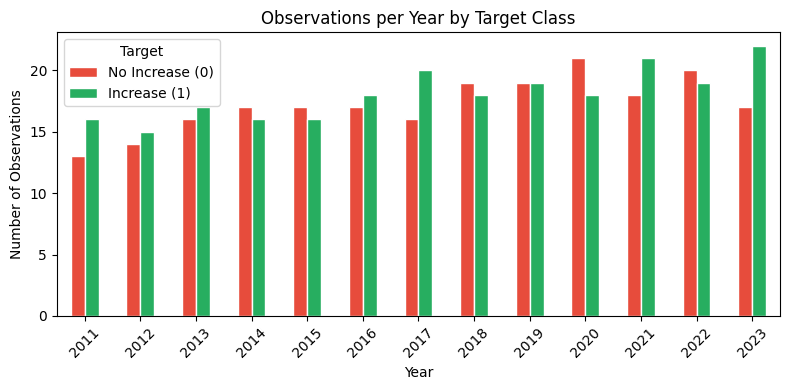

In [11]:
# Per-year observation counts
year_counts = data_clean.groupby("Year").size()
year_class = data_clean.groupby(["Year", "Target"]).size().unstack(fill_value=0)
year_class.columns = ["No Increase (0)", "Increase (1)"]

print("OBSERVATIONS PER YEAR")
print("=" * 50)
print(year_class.to_string())
print(f"\nTotal observations: {len(data_clean)}")

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
year_class.plot(kind="bar", ax=ax, color=["#e74c3c", "#27ae60"], edgecolor="white")
ax.set_title("Observations per Year by Target Class")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Observations")
ax.legend(title="Target")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Per-company summary: year range and observation count
company_summary = data_clean.groupby("Ticker").agg(
    First_Year=("Year", "min"),
    Last_Year=("Year", "max"),
    Observations=("Year", "size")
).sort_values("Ticker")

print("PER-COMPANY SUMMARY (surviving companies only)")
print("=" * 55)
print(company_summary.to_string())

PER-COMPANY SUMMARY (surviving companies only)
        First_Year  Last_Year  Observations
Ticker                                     
AAPL          2011       2023            13
ADBE          2011       2023            13
ADI           2011       2023            13
AMAT          2011       2023            13
AMD           2011       2023            13
AVGO          2011       2023            13
CDNS          2011       2023            13
CRM           2011       2023            13
CRWD          2020       2023             4
CSCO          2011       2023            13
DELL          2017       2023             7
FTNT          2011       2023            13
GOOGL         2011       2023            13
HPE           2016       2023             8
HPQ           2011       2023            13
IBM           2011       2023            13
INTC          2011       2023            13
KLAC          2011       2023            13
LRCX          2011       2023            13
MCHP          2011       2023

In [13]:

export_cols = ["Ticker", "Year", "Price_Momentum", "Price_Range_Ratio", "Volume_Momentum", "Target"]
data_clean[export_cols].to_csv("dividend_dataset.csv", index=False)

print("Dataset saved successfully as 'dividend_dataset.csv'")
print(f"  Shape: {data_clean[export_cols].shape}")
print(f"  Columns: {export_cols}")

Dataset saved successfully as 'dividend_dataset.csv'
  Shape: (459, 6)
  Columns: ['Ticker', 'Year', 'Price_Momentum', 'Price_Range_Ratio', 'Volume_Momentum', 'Target']


In [14]:
print("\nDataset Info:")
print(data_clean.info())

print("\nSummary Statistics:")
print(data_clean.describe())



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 459 entries, 29 to 497
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Ticker             459 non-null    object 
 1   Year               459 non-null    int32  
 2   Price_Momentum     459 non-null    float64
 3   Price_Range_Ratio  459 non-null    float64
 4   Volume_Momentum    459 non-null    float64
 5   Dividend           459 non-null    float64
 6   Target             459 non-null    int64  
dtypes: float64(4), int32(1), int64(1), object(1)
memory usage: 26.9+ KB
None

Summary Statistics:
              Year  Price_Momentum  Price_Range_Ratio  Volume_Momentum  \
count   459.000000      459.000000         459.000000       459.000000   
mean   2017.357298        0.294806           1.836738         0.064413   
std       3.692730        0.500791           0.675572         0.638406   
min    2011.000000       -0.695187           1.204655     


Class Distribution:
Target
1    235
0    224
Name: count, dtype: int64


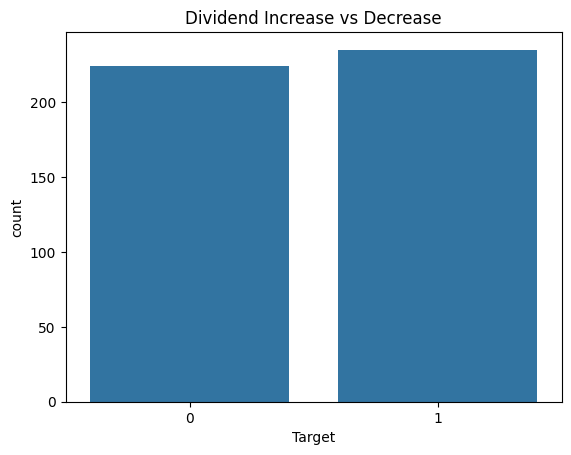

In [15]:
print("\nClass Distribution:")
print(data_clean["Target"].value_counts())

sns.countplot(x="Target", data=data_clean)
plt.title("Dividend Increase vs Decrease")
plt.show()


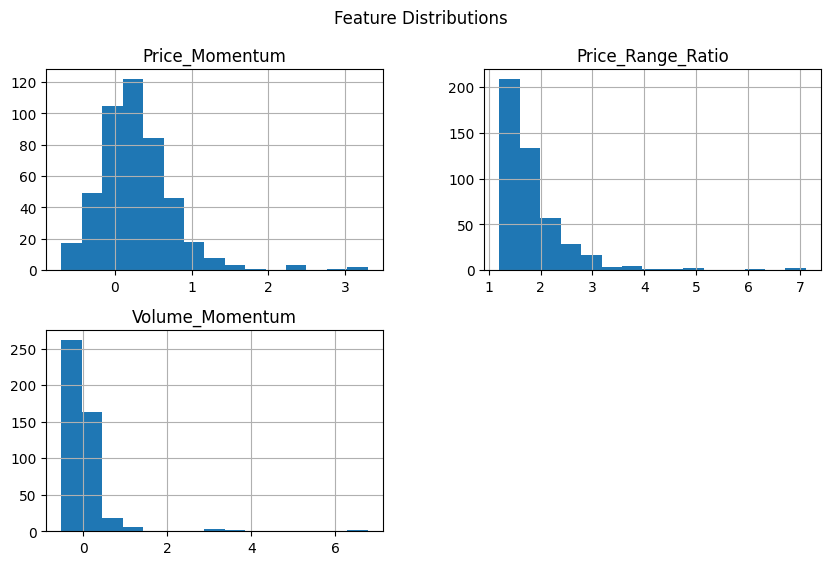

In [16]:
data_clean[["Price_Momentum","Price_Range_Ratio","Volume_Momentum"]].hist(
    figsize=(10,6), bins=15
)
plt.suptitle("Feature Distributions")
plt.show()


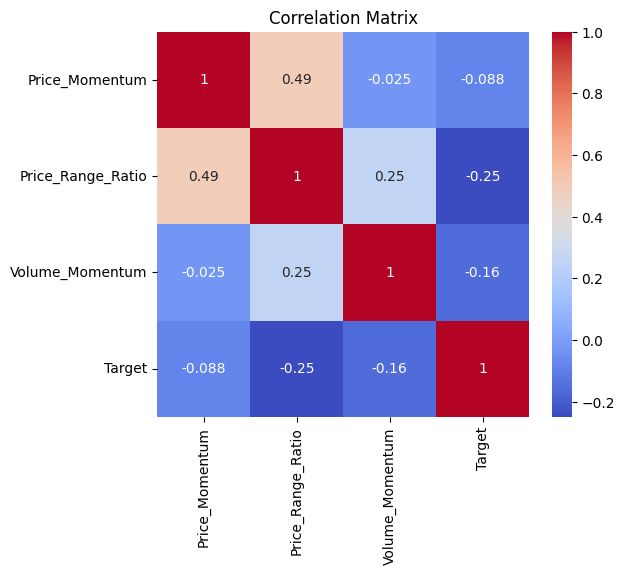

In [17]:
plt.figure(figsize=(6,5))
sns.heatmap(
    data_clean[["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Target"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Matrix")
plt.show()


In [18]:
features = ["Price_Momentum", "Price_Range_Ratio", "Volume_Momentum"]

# Time-based split: train on earlier years, test on later years
# This prevents temporal data leakage where future information leaks into training
split_year = data_clean["Year"].quantile(0.75)
print(f"Train/Test split year: {split_year:.0f}")
print(f"Train: Year <= {split_year:.0f}, Test: Year > {split_year:.0f}")

train_mask = data_clean["Year"] <= split_year
test_mask = data_clean["Year"] > split_year

X_train = data_clean.loc[train_mask, features]
y_train = data_clean.loc[train_mask, "Target"]
X_test = data_clean.loc[test_mask, features]
y_test = data_clean.loc[test_mask, "Target"]

print(f"\nTrain set: {len(X_train)} observations ({y_train.sum()} positive, {(y_train==0).sum()} negative)")
print(f"Test set:  {len(X_test)} observations ({y_test.sum()} positive, {(y_test==0).sum()} negative)")
print(f"Train year range: {data_clean.loc[train_mask, 'Year'].min()} - {data_clean.loc[train_mask, 'Year'].max()}")
print(f"Test year range:  {data_clean.loc[test_mask, 'Year'].min()} - {data_clean.loc[test_mask, 'Year'].max()}")


Train/Test split year: 2021
Train: Year <= 2021, Test: Year > 2021

Train set: 381 observations (194 positive, 187 negative)
Test set:  78 observations (41 positive, 37 negative)
Train year range: 2011 - 2021
Test year range:  2022 - 2023


In [ ]:
# =========================
# Random Forest (Default)
# =========================
default_rf = RandomForestClassifier(random_state=42)
default_rf.fit(X_train, y_train)

# =========================
# Decision Tree (Default)
# =========================
default_dt = DecisionTreeClassifier(random_state=42)
default_dt.fit(X_train, y_train)

# =========================
# Gradient Boosting (Default)
# =========================
default_gb = GradientBoostingClassifier(random_state=42)
default_gb.fit(X_train, y_train)

# =========================
# Logistic Regression (Default)
# =========================
default_lr = LogisticRegression(
    random_state=42,
    max_iter=1000,
    solver="lbfgs"
)
default_lr.fit(X_train, y_train)

# Store default models for later comparison
default_models = {
    "Random Forest (Default)": default_rf,
    "Decision Tree (Default)": default_dt,
    "Gradient Boosting (Default)": default_gb,
    "Logistic Regression (Default)": default_lr
}




Random Forest
Accuracy: 0.5769230769230769
Balanced Accuracy: 0.5764667106130521
AUC: 0.6506262359920897
              precision    recall  f1-score   support

           0       0.55      0.57      0.56        37
           1       0.60      0.59      0.59        41

    accuracy                           0.58        78
   macro avg       0.58      0.58      0.58        78
weighted avg       0.58      0.58      0.58        78



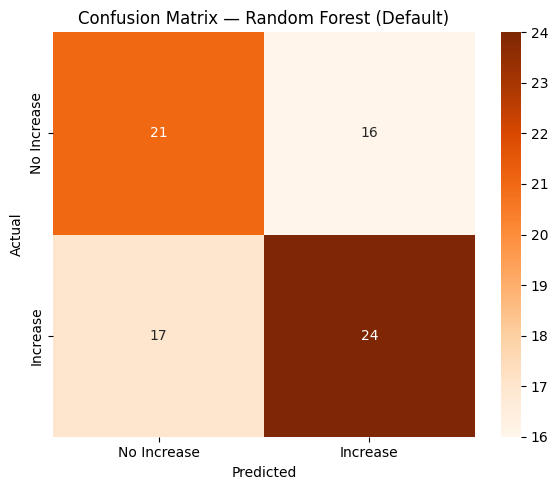


Decision Tree
Accuracy: 0.5897435897435898
Balanced Accuracy: 0.5833882663150955
AUC: 0.5833882663150955
              precision    recall  f1-score   support

           0       0.59      0.46      0.52        37
           1       0.59      0.71      0.64        41

    accuracy                           0.59        78
   macro avg       0.59      0.58      0.58        78
weighted avg       0.59      0.59      0.58        78



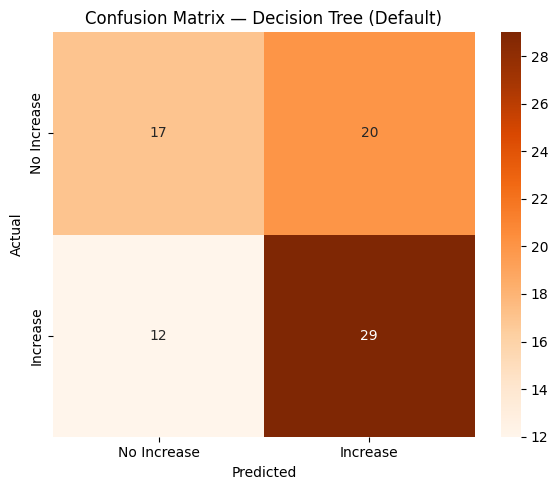


Gradient Boosting
Accuracy: 0.5256410256410257
Balanced Accuracy: 0.51977587343441
AUC: 0.4907712590639419
              precision    recall  f1-score   support

           0       0.50      0.41      0.45        37
           1       0.54      0.63      0.58        41

    accuracy                           0.53        78
   macro avg       0.52      0.52      0.52        78
weighted avg       0.52      0.53      0.52        78



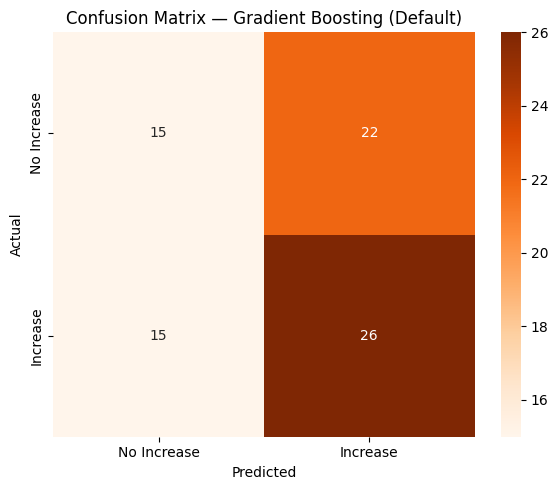


Logistic Regression
Accuracy: 0.6923076923076923
Balanced Accuracy: 0.6901779828609097
AUC: 0.7923533289386947
              precision    recall  f1-score   support

           0       0.69      0.65      0.67        37
           1       0.70      0.73      0.71        41

    accuracy                           0.69        78
   macro avg       0.69      0.69      0.69        78
weighted avg       0.69      0.69      0.69        78



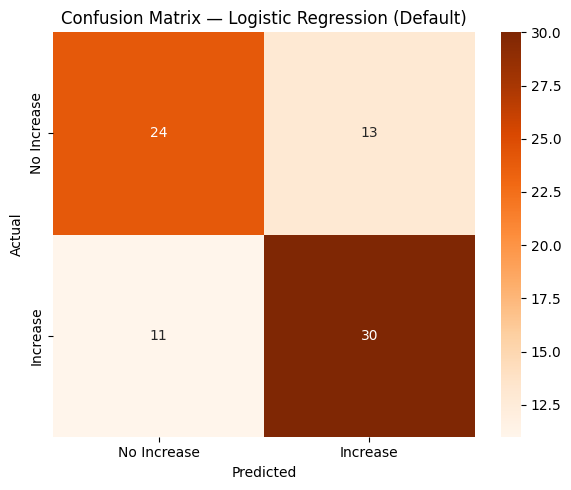


Model Comparison Table:

                 Model  Accuracy  Balanced Accuracy       AUC
0        Random Forest  0.576923           0.576467  0.650626
1        Decision Tree  0.589744           0.583388  0.583388
2    Gradient Boosting  0.525641           0.519776  0.490771
3  Logistic Regression  0.692308           0.690178  0.792353


In [20]:
models = {
    "Random Forest": default_rf,
    "Decision Tree": default_dt,
    "Gradient Boosting": default_gb,
    "Logistic Regression": default_lr
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)

    results.append([name, acc, bal_acc, auc_score])

    print("\n====================")
    print(name)
    print("====================")
    print("Accuracy:", acc)
    print("Balanced Accuracy:", bal_acc)
    print("AUC:", auc_score)

    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
                xticklabels=["No Increase", "Increase"],
                yticklabels=["No Increase", "Increase"])
    plt.title(f"Confusion Matrix — {name} (Default)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# Comparison table
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Balanced Accuracy", "AUC"]
)

print("\nModel Comparison Table:\n")
print(results_df)


In [21]:
# ------------------------------------------------------------------
# 5-Fold expanding-window CV by year
# ------------------------------------------------------------------
train_years = sorted(data_clean.loc[train_mask, "Year"].unique())
n_folds = 5
val_start = len(train_years) - n_folds

year_cv = []
for i in range(val_start, len(train_years)):
    tr_years = train_years[:i]
    val_year = train_years[i]
    tr_idx = np.where(data_clean.loc[train_mask, "Year"].isin(tr_years))[0]
    val_idx = np.where(data_clean.loc[train_mask, "Year"] == val_year)[0]
    year_cv.append((tr_idx, val_idx))
    print(f"  Fold {len(year_cv)}: train {tr_years[0]}-{tr_years[-1]}, "
          f"val {val_year}  (train={len(tr_idx)}, val={len(val_idx)})")
print(f"Total CV folds: {len(year_cv)}")

n_iter = 300

# =========================
# Random Forest
# =========================
rf_pipe = SkPipeline([
    ("clf", RandomForestClassifier(random_state=42))
])

rf_grid = RandomizedSearchCV(
    rf_pipe,
    {
        "clf__n_estimators": randint(50, 800),
        "clf__max_depth": [3, 5, 7, 10, 15, 20, 30, None],
        "clf__min_samples_split": randint(2, 30),
        "clf__min_samples_leaf": randint(1, 15),
        "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, 0.9, 1.0],
        "clf__bootstrap": [True, False],
        "clf__class_weight": ["balanced", "balanced_subsample", None]
    },
    n_iter=n_iter,
    cv=year_cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42
)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_
print(f"RF best params: {rf_grid.best_params_}")
print(f"RF best CV balanced accuracy: {rf_grid.best_score_:.4f}")

# =========================
# Decision Tree
# =========================
dt_pipe = SkPipeline([
    ("clf", DecisionTreeClassifier(random_state=42))
])

dt_grid = RandomizedSearchCV(
    dt_pipe,
    {
        "clf__max_depth": [3, 5, 7, 10, 15, 20, 30, None],
        "clf__min_samples_split": randint(2, 30),
        "clf__min_samples_leaf": randint(1, 15),
        "clf__criterion": ["gini", "entropy", "log_loss"],
        "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, 0.9, None],
        "clf__class_weight": ["balanced", None]
    },
    n_iter=n_iter,
    cv=year_cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42
)
dt_grid.fit(X_train, y_train)
best_dt = dt_grid.best_estimator_
print(f"DT best params: {dt_grid.best_params_}")
print(f"DT best CV balanced accuracy: {dt_grid.best_score_:.4f}")

# =========================
# Gradient Boosting
# =========================
gb_pipe = SkPipeline([
    ("clf", GradientBoostingClassifier(random_state=42))
])

gb_grid = RandomizedSearchCV(
    gb_pipe,
    {
        "clf__n_estimators": randint(50, 800),
        "clf__learning_rate": uniform(0.005, 0.3),
        "clf__max_depth": [2, 3, 4, 5, 7, 10, 15],
        "clf__min_samples_split": randint(2, 30),
        "clf__min_samples_leaf": randint(1, 15),
        "clf__subsample": uniform(0.5, 0.5),
        "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, 0.9],
        "clf__loss": ["log_loss", "exponential"]
    },
    n_iter=n_iter,
    cv=year_cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42
)
gb_grid.fit(X_train, y_train)
best_gb = gb_grid.best_estimator_
print(f"GB best params: {gb_grid.best_params_}")
print(f"GB best CV balanced accuracy: {gb_grid.best_score_:.4f}")

# =========================
# Logistic Regression
# =========================
lr_pipe = SkPipeline([
    ("clf", LogisticRegression(random_state=42, max_iter=5000))
])

lr_param_dist = [
    {
        "clf__solver": ["liblinear"],
        "clf__penalty": ["l1", "l2"],
        "clf__C": loguniform(1e-3, 1e2),
        "clf__class_weight": ["balanced", None],
    },
    {
        "clf__solver": ["saga"],
        "clf__penalty": ["l1", "l2"],
        "clf__C": loguniform(1e-3, 1e2),
        "clf__class_weight": ["balanced", None],
    },
    {
        "clf__solver": ["saga"],
        "clf__penalty": ["elasticnet"],
        "clf__C": loguniform(1e-3, 1e2),
        "clf__l1_ratio": uniform(0, 1),  # only sampled when penalty == "elasticnet"
        "clf__class_weight": ["balanced", None],
    },
    {
        "clf__solver": ["lbfgs", "newton-cg"],
        "clf__penalty": ["l2"],
        "clf__C": loguniform(1e-3, 1e2),
        "clf__class_weight": ["balanced", None],
    },
]

lr_grid = RandomizedSearchCV(
    lr_pipe,
    lr_param_dist,
    n_iter=400,
    cv=year_cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42
)
lr_grid.fit(X_train, y_train)
best_lr = lr_grid.best_estimator_
print(f"LR best params: {lr_grid.best_params_}")
print(f"LR best CV balanced accuracy: {lr_grid.best_score_:.4f}")

  Fold 1: train 2011-2016, val 2017  (train=192, val=36)
  Fold 2: train 2011-2017, val 2018  (train=228, val=37)
  Fold 3: train 2011-2018, val 2019  (train=265, val=38)
  Fold 4: train 2011-2019, val 2020  (train=303, val=39)
  Fold 5: train 2011-2020, val 2021  (train=342, val=39)
Total CV folds: 5
RF best params: {'clf__bootstrap': True, 'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 8, 'clf__min_samples_split': 16, 'clf__n_estimators': 206}
RF best CV balanced accuracy: 0.6148
DT best params: {'clf__class_weight': 'balanced', 'clf__criterion': 'log_loss', 'clf__max_depth': 3, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 5}
DT best CV balanced accuracy: 0.6175
GB best params: {'clf__learning_rate': np.float64(0.1037154096109613), 'clf__loss': 'log_loss', 'clf__max_depth': 7, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 11, 'clf__min_samples_split': 3, 'clf__n_estimators': 173, 'clf

In [22]:
models = {
    "Random Forest": best_rf,
    "Decision Tree": best_dt,
    "Gradient Boosting": best_gb,
    "Logistic Regression": best_lr
}

results = []

for name, model in models.items():
    # model is already fitted inside the pipeline from Cell 21's
    # RandomizedSearchCV(refit=True) — do NOT call .fit() again here.

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)

    results.append([name, acc, bal_acc, auc_score])

    print("\n====================")
    print(name)
    print("====================")
    print("Accuracy:", acc)
    print("Balanced Accuracy:", bal_acc)
    print("AUC:", auc_score)

    print(classification_report(y_test, y_pred))

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Balanced Accuracy", "AUC"])
print("\nModel Comparison Table:\n")
print(results_df)


Random Forest
Accuracy: 0.5769230769230769
Balanced Accuracy: 0.587013843111404
AUC: 0.6947923533289387
              precision    recall  f1-score   support

           0       0.54      0.78      0.64        37
           1       0.67      0.39      0.49        41

    accuracy                           0.58        78
   macro avg       0.60      0.59      0.56        78
weighted avg       0.61      0.58      0.56        78


Decision Tree
Accuracy: 0.6410256410256411
Balanced Accuracy: 0.6545814106789717
AUC: 0.6723796967699407
              precision    recall  f1-score   support

           0       0.58      0.92      0.71        37
           1       0.84      0.39      0.53        41

    accuracy                           0.64        78
   macro avg       0.71      0.65      0.62        78
weighted avg       0.72      0.64      0.62        78


Gradient Boosting
Accuracy: 0.5
Balanced Accuracy: 0.49538562953197096
AUC: 0.5398813447593935
              precision    recall  f1-s

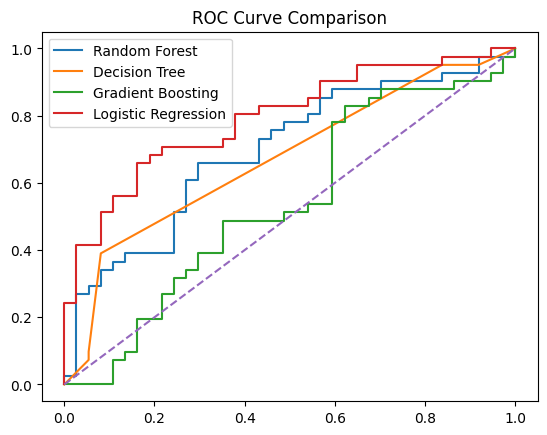

In [23]:
plt.figure()

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve Comparison")
plt.show()


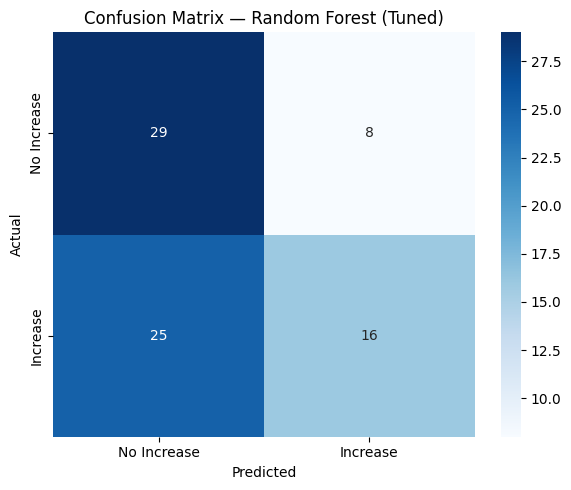

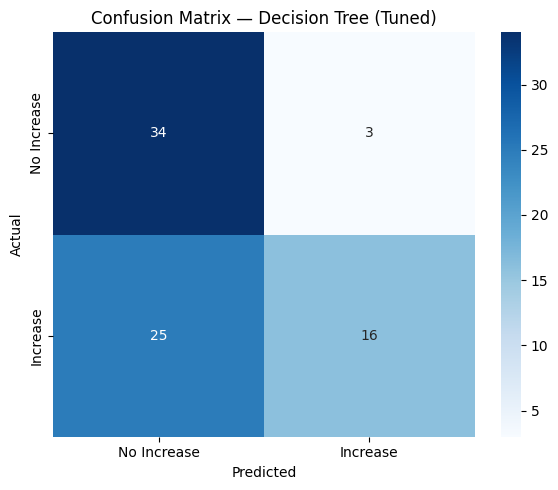

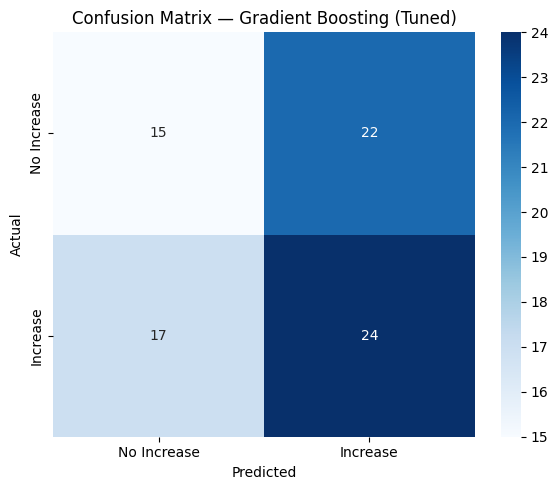

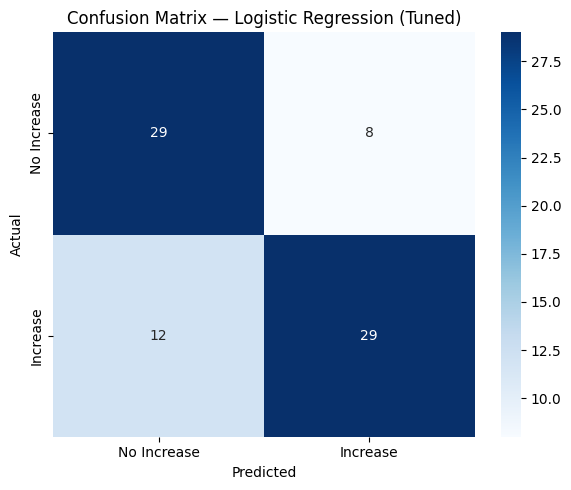

In [24]:
tuned_models_dict = {
    "Random Forest (Tuned)": best_rf,
    "Decision Tree (Tuned)": best_dt,
    "Gradient Boosting (Tuned)": best_gb,
    "Logistic Regression (Tuned)": best_lr
}

for name, model in tuned_models_dict.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["No Increase", "Increase"],
                yticklabels=["No Increase", "Increase"])
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


In [25]:
from sklearn.model_selection import cross_val_score

cv_scores = {
    "RF (Tuned)":  rf_grid.best_score_,
    "DT (Tuned)":  dt_grid.best_score_,
    "GB (Tuned)":  gb_grid.best_score_,
    "LR (Tuned)":  lr_grid.best_score_,
}

default_pipelines_for_cv = {
    "RF (Default)": RandomForestClassifier(random_state=42),
    "DT (Default)": DecisionTreeClassifier(random_state=42),
    "GB (Default)": GradientBoostingClassifier(random_state=42),
    "LR (Default)": LogisticRegression(random_state=42, max_iter=1000)
}
for label, model in default_pipelines_for_cv.items():
    scores = cross_val_score(model, X_train, y_train, cv=year_cv, scoring="balanced_accuracy")
    cv_scores[label] = scores.mean()

print("CV Balanced Accuracy (all candidates):")
for name, score in sorted(cv_scores.items(), key=lambda x: -x[1]):
    print(f"  {name:25s}  {score:.4f}")

# ------------------------------------------------------------------
# DEFAULT vs TUNED MODEL COMPARISON
# NOTE: CV bal. acc. is the UNBIASED selection metric.
#       Test metrics are reported for transparency but were NOT
#       used to pick the best model.
# ------------------------------------------------------------------
all_compare = {
    "RF (Default)": default_models["Random Forest (Default)"],
    "RF (Tuned)": best_rf,
    "DT (Default)": default_models["Decision Tree (Default)"],
    "DT (Tuned)": best_dt,
    "GB (Default)": default_models["Gradient Boosting (Default)"],
    "GB (Tuned)": best_gb,
    "LR (Default)": default_lr,
    "LR (Tuned)": best_lr
}

comparison = []
for name, model in all_compare.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    auc_val = roc_auc_score(y_test, y_prob)
    cr = classification_report(y_test, y_pred, output_dict=True)
    f1_0 = cr["0"]["f1-score"]
    f1_1 = cr["1"]["f1-score"]
    comparison.append({
        "Model": name,
        "CV Bal. Acc.": round(cv_scores[name], 4),
        "Test Acc.": round(acc, 4),
        "Test Bal. Acc.": round(bal_acc, 4),
        "Test AUC": round(auc_val, 4),
        "F1 (Class 0)": round(f1_0, 4),
        "F1 (Class 1)": round(f1_1, 4)
    })

comp_df = pd.DataFrame(comparison)
print("DEFAULT vs TUNED MODEL COMPARISON")
print("=" * 120)
print("Selection metric: CV Balanced Accuracy (unbiased)")
print("Test metrics shown for transparency only.")
print()
print(comp_df.to_string(index=False))

CV Balanced Accuracy (all candidates):
  LR (Tuned)                 0.6218
  GB (Tuned)                 0.6206
  DT (Tuned)                 0.6175
  RF (Tuned)                 0.6148
  LR (Default)               0.5918
  GB (Default)               0.5802
  RF (Default)               0.5607
  DT (Default)               0.5099
DEFAULT vs TUNED MODEL COMPARISON
Selection metric: CV Balanced Accuracy (unbiased)
Test metrics shown for transparency only.

       Model  CV Bal. Acc.  Test Acc.  Test Bal. Acc.  Test AUC  F1 (Class 0)  F1 (Class 1)
RF (Default)        0.5607     0.5769          0.5765    0.6506        0.5600        0.5926
  RF (Tuned)        0.6148     0.5769          0.5870    0.6948        0.6374        0.4923
DT (Default)        0.5099     0.5897          0.5834    0.5834        0.5152        0.6444
  DT (Tuned)        0.6175     0.6410          0.6546    0.6724        0.7083        0.5333
GB (Default)        0.5802     0.5256          0.5198    0.4908        0.4478        0

In [ ]:
# ------------------------------------------------------------------
# Save all candidate models and pick the primary one DYNAMICALLY by
# CV balanced accuracy (cv_scores, computed in Cell 25) across BOTH
# default and tuned candidates -- no hardcoding.
#

# ------------------------------------------------------------------
import joblib

# Save all tuned pipelines
joblib.dump(best_rf, "dividend_prediction_model_rf_tuned.pkl")
joblib.dump(best_dt, "dividend_prediction_model_dt_tuned.pkl")
joblib.dump(best_gb, "dividend_prediction_model_gb_tuned.pkl")
joblib.dump(best_lr, "dividend_prediction_model_lr_tuned.pkl")

# Save all default models
joblib.dump(default_rf, "dividend_prediction_model_rf_default.pkl")
joblib.dump(default_dt, "dividend_prediction_model_dt_default.pkl")
joblib.dump(default_gb, "dividend_prediction_model_gb_default.pkl")
joblib.dump(default_lr, "dividend_prediction_model_lr_default.pkl")

# Map each cv_scores name -> (fitted model object, X_test)
candidates = {
    "RF (Tuned)":   (best_rf,     X_test),
    "DT (Tuned)":   (best_dt,     X_test),
    "GB (Tuned)":   (best_gb,     X_test),
    "LR (Tuned)":   (best_lr,     X_test),
    "RF (Default)": (default_rf,  X_test),
    "DT (Default)": (default_dt,  X_test),
    "GB (Default)": (default_gb,  X_test),
    "LR (Default)": (default_lr,  X_test),
}

# Pick the winner purely from CV balanced accuracy across ALL 8 candidates
best_model_name = max(cv_scores, key=cv_scores.get)
best_model, _ = candidates[best_model_name]

print("CV Balanced Accuracy (all candidates):")
for name, score in sorted(cv_scores.items(), key=lambda x: -x[1]):
    marker = "  <-- selected" if name == best_model_name else ""
    print(f"  {name:15s}  {score:.4f}{marker}")

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(f"\nPrimary model: {best_model_name}")
print(f"Held-out test bal. acc.: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Held-out test AUC:       {roc_auc_score(y_test, y_prob):.4f}")

# Save primary model for export
joblib.dump(best_model, "dividend_prediction_model.pkl")

test_dataset = X_test.copy()
test_dataset["Target"] = y_test
test_dataset.to_csv("dividend_test_dataset.csv", index=False)

model_type = (
    type(best_model.named_steps["clf"]).__name__
    if hasattr(best_model, "named_steps")
    else type(best_model).__name__
)
print(f"\nSaved files:")
print(f"  dividend_prediction_model.pkl             ({best_model_name} - primary, clf type: {model_type})")
print(f"  dividend_prediction_model_rf_tuned.pkl")
print(f"  dividend_prediction_model_dt_tuned.pkl")
print(f"  dividend_prediction_model_gb_tuned.pkl")
print(f"  dividend_prediction_model_lr_tuned.pkl")
print(f"  dividend_prediction_model_rf_default.pkl")
print(f"  dividend_prediction_model_dt_default.pkl")
print(f"  dividend_prediction_model_gb_default.pkl")
print(f"  dividend_prediction_model_lr_default.pkl")
print(f"  dividend_test_dataset.csv")

CV Balanced Accuracy (all candidates):
  LR (Tuned)       0.6218  <-- selected
  GB (Tuned)       0.6206
  DT (Tuned)       0.6175
  RF (Tuned)       0.6148
  LR (Default)     0.5918
  GB (Default)     0.5802
  RF (Default)     0.5607
  DT (Default)     0.5099

Primary model: LR (Tuned)
Held-out test bal. acc.: 0.7456
Held-out test AUC:       0.7937

Saved files:
  dividend_prediction_model.pkl             (LR (Tuned) - primary, clf type: LogisticRegression)
  dividend_prediction_model_rf_tuned.pkl
  dividend_prediction_model_dt_tuned.pkl
  dividend_prediction_model_gb_tuned.pkl
  dividend_prediction_model_lr_tuned.pkl
  dividend_prediction_model_rf_default.pkl
  dividend_prediction_model_dt_default.pkl
  dividend_prediction_model_gb_default.pkl
  dividend_prediction_model_lr_default.pkl
  dividend_test_dataset.csv


In [27]:
print("DATA LEAKAGE CHECK")
print("=" * 60)

# 1. Check train/test year overlap
train_years = set(data_clean.loc[train_mask, "Year"].unique())
test_years = set(data_clean.loc[test_mask, "Year"].unique())
overlap = train_years & test_years
print(f"\n1. Train year range: {min(train_years)} - {max(train_years)}")
print(f"   Test year range:  {min(test_years)} - {max(test_years)}")
if overlap:
    print(f"   WARNING: Year overlap detected: {sorted(overlap)}")
else:
    print(f"   OK: No year overlap between train and test.")

# 2. Check for target leakage in features
print(f"\n2. Feature columns used: {features}")
leakage_keywords = ["dividend", "next", "target", "change"]
found_leak = False
for f in features:
    for kw in leakage_keywords:
        if kw in f.lower():
            print(f"   WARNING: Feature '{f}' may contain leakage (matches '{kw}')")
            found_leak = True
if not found_leak:
    print("   OK: No dividend or target-related columns in features.")

# 3. Check class imbalance handling does not touch the test set
print(f"\n3. Class imbalance handling: class_weight='balanced' (no resampling)")
print(f"   Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print("   OK: No synthetic sample generation is used, so there is no")
print("       resampling step that could leak information into the test set.")

# 4. Check feature statistics between train and test
print(f"\n4. Feature distribution comparison (train vs test):")
for f in features:
    train_mean = X_train[f].mean()
    test_mean = X_test[f].mean()
    diff = abs(train_mean - test_mean)
    status = "OK" if diff < 0.5 else "CHECK"
    print(f"   {f}: train_mean={train_mean:.4f}, test_mean={test_mean:.4f}, diff={diff:.4f} [{status}]")

# 5. Check Dividend_Change not in data
print(f"\n5. Checking for Dividend_Change column...")
if "Dividend_Change" in data_clean.columns:
    print("   WARNING: Dividend_Change column exists in dataset!")
else:
    print("   OK: Dividend_Change not present in dataset.")

# 6. Check no same-year prediction
print(f"\n6. Checking prediction direction (genuine future prediction)...")
print("   Target = 1 if Next_Year_Dividend > Current_Dividend")
print("   OK: Target uses shifted dividend (year t+1 vs year t).")

print(f"\n{'=' * 60}")
print("LEAKAGE CHECK COMPLETE")

DATA LEAKAGE CHECK

1. Train year range: 2011 - 2021
   Test year range:  2022 - 2023
   OK: No year overlap between train and test.

2. Feature columns used: ['Price_Momentum', 'Price_Range_Ratio', 'Volume_Momentum']
   OK: No dividend or target-related columns in features.

3. Class imbalance handling: class_weight='balanced' (no resampling)
   Train shape: (381, 3), Test shape: (78, 3)
   OK: No synthetic sample generation is used, so there is no
       resampling step that could leak information into the test set.

4. Feature distribution comparison (train vs test):
   Price_Momentum: train_mean=0.3197, test_mean=0.1733, diff=0.1463 [OK]
   Price_Range_Ratio: train_mean=1.8063, test_mean=1.9855, diff=0.1793 [OK]
   Volume_Momentum: train_mean=0.0660, test_mean=0.0565, diff=0.0095 [OK]

5. Checking for Dividend_Change column...
   OK: Dividend_Change not present in dataset.

6. Checking prediction direction (genuine future prediction)...
   Target = 1 if Next_Year_Dividend > Current

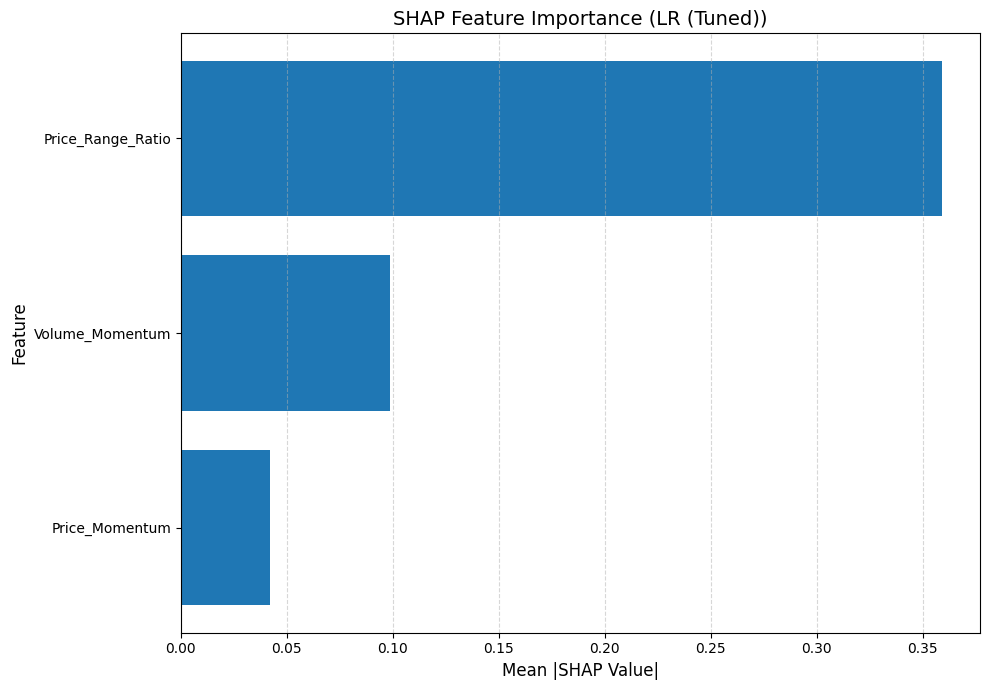

,Feature,Importance
1,Price_Range_Ratio,0.359097
2,Volume_Momentum,0.098724
0,Price_Momentum,0.042020


In [28]:
# FIX: best_model can now be either an sklearn or imblearn Pipeline
shap_model = best_model.named_steps["clf"] if isinstance(best_model, (SkPipeline, ImbPipeline)) else best_model


explainer = shap.Explainer(shap_model, X_train)
shap_explanation = explainer(X_test)
shap_values = shap_explanation.values

# Convert to numpy array if needed
if isinstance(shap_values, list):
    # Older SHAP versions
    if len(shap_values) == 2:
        # Binary classification -> positive class
        shap_values = shap_values[1]
    else:
        # Multiclass -> average over classes
        shap_values = np.mean(np.abs(np.array(shap_values)), axis=0)
else:
    shap_values = np.array(shap_values)

# Handle different output shapes
if shap_values.ndim == 3:
    # Shape could be (samples, features, classes)
    if shap_values.shape[2] == 2:
        shap_values = shap_values[:, :, 1]
    else:
        shap_values = np.mean(np.abs(shap_values), axis=2)

elif shap_values.ndim == 1:
    shap_values = shap_values.reshape(-1, 1)

# Compute mean absolute SHAP importance
importance = np.abs(shap_values).mean(axis=0)

# Flatten if still not 1D
importance = np.ravel(importance)

# Safety check
if len(importance) != len(X_test.columns):
    raise ValueError(
        f"Number of SHAP importances ({len(importance)}) "
        f"does not match number of features ({len(X_test.columns)}).\n"
        f"SHAP shape: {np.array(shap_values).shape}"
    )

# Create dataframe
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

# Plot
plt.figure(figsize=(10, 7))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Mean |SHAP Value|", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.title(f"SHAP Feature Importance ({best_model_name})", fontsize=14)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Display feature importance table
display(feature_importance)

In [29]:
loaded_model = joblib.load("dividend_prediction_model.pkl")
test_data = pd.read_csv("dividend_test_dataset.csv")

features = ["Price_Momentum", "Price_Range_Ratio", "Volume_Momentum"]
X_loaded = test_data[features]
y_actual = test_data["Target"]

y_predicted = loaded_model.predict(X_loaded)

results = test_data[["Price_Momentum", "Price_Range_Ratio", "Volume_Momentum"]].copy()
results["Actual"] = y_actual.values
results["Predicted"] = y_predicted
results["Correct"] = results["Actual"] == results["Predicted"]

print("PREDICTION RESULTS (Loaded Model vs Test Set)")
print("=" * 60)
print(results.to_string(index=True))
print(f"\nTotal: {len(results)} | Correct: {results['Correct'].sum()} | Incorrect: {(~results['Correct']).sum()}")



PREDICTION RESULTS (Loaded Model vs Test Set)
    Price_Momentum  Price_Range_Ratio  Volume_Momentum  Actual  Predicted  Correct
0        -0.264042           1.445018        -0.032733       1          1     True
1        -0.406535           2.092964         0.493830       0          0     True
2        -0.049123           1.354144         0.026685       1          1     True
3        -0.375426           2.333074        -0.020392       1          0    False
4        -0.549896           2.793110         0.776620       0          0     True
5        -0.132697           1.582092         0.258412       1          1     True
6        -0.137966           1.473473         0.191324       0          1    False
7        -0.478259           2.033165         0.240847       0          0     True
8        -0.485763           2.451874         0.186404       0          0     True
9        -0.224627           1.591245         0.099221       1          1     True
10       -0.266330           1.843216    